# Caps and floors : pricing tests

A cap is a strip of caplets: the caplet on $[t_{i-1}, t_i]$ pays $N \tau_i (L_i - K)^+$ at $t_i$, where the
EURIBOR 6M rate $L_i$ fixes at $t_{i-1}$ (floorlet: $(K - L_i)^+$). The first period of a spot cap is excluded.
Market models (`Fixed_Income_Models/rate_pricing.py`):
$$
\text{Caplet} = N \tau_i P(0,t_i)\; \mathbb{E}\left[(F_i(t_{i-1}) - K)^+\right],
$$
with $F_i$ normal (**Bachelier**, the market standard since negative rates), lognormal (**Black**) or lognormal
after a shift (**shifted Black**). Then the **Hull-White** model (`hull_white_1F.py`), where a caplet is a put on a
zero-coupon bond.

> **The volatilities are illustrative.** No volatility quotes are available in `Data/`: the normal volatilities
> of `rates_market.py` are assumptions of the order of magnitude of EUR volatilities in early 2025 (70 to 90bp),
> with a flat smile. The curve is the EURIBOR 6M curve of 12/02/2025 (single-curve: it discounts and projects).

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models package
sys.path.append(os.path.abspath(".."))                       # Produits : rate_products.py, rates_market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rates_market import eur_curve, illustrative_cap_vols, illustrative_swaption_vols
from rate_products import Swap, CapFloor, Swaption
from Fixed_Income_Models import (RatePricer, HullWhite, curve_risk, key_rate_risk, vega, bachelier, black,
                                 option_value, implied_vol)

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
curve = eur_curve()

In [2]:
cap_vols = illustrative_cap_vols()
pricer = RatePricer(curve, cap_vols, model="bachelier")
cap, floor = CapFloor(5, 0.025, is_cap=True), CapFloor(5, 0.025, is_cap=False)
pd.DataFrame({"flat normal vol (bp)": 1e4 * cap_vols.vols}, index=pd.Index(cap_vols.maturities, name="cap maturity (y)")).T

cap maturity (y),1,2,3,4,5,7,10
flat normal vol (bp),72,82,86,87,86,84,80


## 1. Payoffs and caplet decomposition

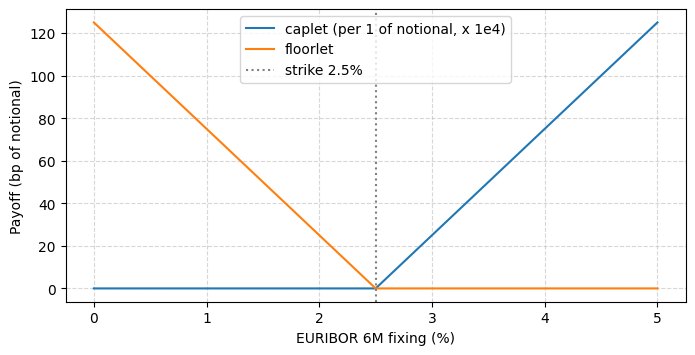

Cap 5y(K=2.5000%, 9 periods, N=1,000,000)


,fixing,payment,forward (%),vol,value,delta (per bp of forward),vega (per bp of vol)
0,0.5,1,2.1616,0.0086,537.448,14.1143,11.8033
1,1,1.5,2.13128,0.0086,917.312,16.1459,17.589
2,1.5,2,2.19192,0.0086,"1,357.82",18.4045,22.3816
3,2,2.5,2.30316,0.0086,"1,858.11",20.5941,26.3195
4,2.5,3,2.32339,0.0086,"2,143.33",20.9471,29.2241
5,3,3.5,2.34363,0.0086,"2,398.35",21.16,31.7353
6,3.5,4,2.36386,0.0086,"2,629.38",21.282,33.9431
7,4,4.5,2.3841,0.0086,"2,840.6",21.3404,35.9062
8,4.5,5,2.40434,0.0086,"3,034.98",21.3522,37.6656


In [3]:
L = np.linspace(0.0, 0.05, 501)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(100 * L, 1e4 * np.maximum(L - 0.025, 0) * 0.5, label="caplet (per 1 of notional, x 1e4)")
ax.plot(100 * L, 1e4 * np.maximum(0.025 - L, 0) * 0.5, label="floorlet")
ax.axvline(2.5, color="grey", linestyle=":", label="strike 2.5%")
ax.set_xlabel("EURIBOR 6M fixing (%)"); ax.set_ylabel("Payoff (bp of notional)"); ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.show()
print(cap)
pricer.caplet_table(cap)

## 2. Validation

- **Cap-floor parity**: Cap - Floor = payer swap with the same schedule and fixed rate = strike (model free).
- The Black and shifted Black models with the volatilities implied from the Bachelier prices give back the same prices.
- **Hull-White**: the same parity, and the Monte Carlo price of a caplet against the closed form.

In [4]:
hw = HullWhite(curve, a=0.03, sigma=0.0085)
fixing, payment = 2.0, 2.5
caplet = CapFloor(payment, 0.025, start=fixing, skip_first=False)
X, D = hw.simulate(np.array([fixing]), 400_000, seed=3)
P = hw.bond_price(fixing, payment, X[0])
L_mc = (1 / P - 1) / 0.5
mc = caplet.notional * 0.5 * np.maximum(L_mc - 0.025, 0) * P * D[0]
checks = {"Bachelier : cap - floor - swap": pricer.price(cap) - pricer.price(floor) - pricer.price(cap.swap()),
          "Hull-White : cap - floor - swap": hw.price(cap) - hw.price(floor) - pricer.price(cap.swap()),
          "Hull-White caplet : MC - closed form": mc.mean() - hw.price(caplet),
          "  (MC standard error)": mc.std() / np.sqrt(len(mc))}
pd.Series(checks, name="value").to_frame()

,value
Bachelier : cap - floor - swap,1.09139e-11
Hull-White : cap - floor - swap,5.20231e-10
Hull-White caplet : MC - closed form,-0.914753
(MC standard error),4.52567


In [5]:
fixings, payments, forwards, weights = pricer._caplet_inputs(cap)
normal = pricer.caplet_vols(cap)
values = weights * bachelier(forwards, cap.strike, normal, fixings)
black_vols = [implied_vol(v / w, F, cap.strike, t, True, "black") for v, w, F, t in zip(values, weights, forwards, fixings)]
shifted_vols = [implied_vol(v / w, F, cap.strike, t, True, "shifted_black", 0.03) for v, w, F, t in zip(values, weights, forwards, fixings)]
table = pd.DataFrame({"fixing": fixings, "forward (%)": 100 * forwards, "normal vol (bp)": 1e4 * normal,
                      "Black vol (%)": 100 * np.array(black_vols), "shifted Black vol, 3% (%)": 100 * np.array(shifted_vols)})
for name, vols, model, shift in [("Black", black_vols, "black", 0.0), ("shifted Black", shifted_vols, "shifted_black", 0.03)]:
    table[f"{name} price - Bachelier"] = weights * option_value(model, forwards, cap.strike, np.array(vols), fixings, True, shift) - values
table

,fixing,forward (%),normal vol (bp),Black vol (%),"shifted Black vol, 3% (%)",Black price - Bachelier,shifted Black price - Bachelier
0,0.5,2.1616,86,37.0681,16.1469,-2.27374e-13,5.68434e-13
1,1,2.13128,86,37.435,16.2029,-3.41061e-13,-1.59162e-12
2,1.5,2.19192,86,37.0263,16.1175,2.251e-11,2.67391e-10
3,2,2.30316,86,36.222,15.9568,4.54747e-13,4.54747e-13
4,2.5,2.32339,86,36.1621,15.935,7.23048e-11,9.09495e-13
5,3,2.34363,86,36.1026,15.9132,-9.09495e-13,0
6,3.5,2.36386,86,36.0435,15.8915,4.54747e-13,-2.30375e-09
7,4,2.3841,86,35.9847,15.8698,-1.81899e-12,-1.27329e-11
8,4.5,2.40434,86,35.9263,15.8483,2.04636e-11,-4.54747e-13


## 3. Flat vols and spot (caplet) vols

A flat vol is one volatility for all the caplets of a cap; spot vols are the caplet volatilities. They are
stripped from the flat vols, piecewise constant between cap maturities, so that every at-the-money cap is
repriced. The flat vol curve is an average of the spot vols: the spot vols are more humped.

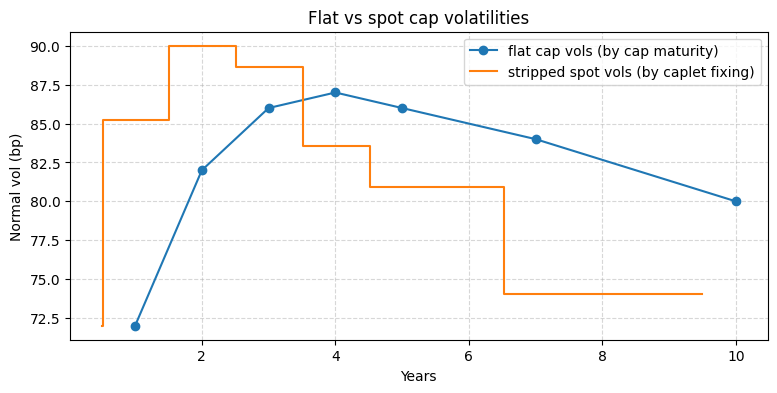

,flat vols,spot vols
ATM cap 2y (K = 2.161%),"4,628.55","4,628.55"
ATM cap 3y (K = 2.221%),"9,708.04","9,708.04"
ATM cap 4y (K = 2.258%),"15,584.2","15,584.2"
ATM cap 5y (K = 2.287%),"21,771.2","21,771.2"
ATM cap 7y (K = 2.323%),"35,186.7","35,186.7"
ATM cap 10y (K = 2.348%),"55,914.3","55,914.3"


In [6]:
spot_pricer = RatePricer(curve, cap_vols, model="bachelier", cap_vol_type="spot")
spot = spot_pricer.spot_vols(2)
t = np.linspace(0.5, 9.5, 400)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cap_vols.maturities, 1e4 * cap_vols.vols, "o-", label="flat cap vols (by cap maturity)")
ax.step(t, [1e4 * spot(x) for x in t], where="post", label="stripped spot vols (by caplet fixing)")
ax.set_xlabel("Years"); ax.set_ylabel("Normal vol (bp)"); ax.set_title("Flat vs spot cap volatilities")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.show()
rows = {}
for T in cap_vols.maturities[1:]:
    c = CapFloor(T, 0.0); c = c.with_strike(pricer.par_rate(c.swap()))
    rows[f"ATM cap {T:g}y (K = {100 * c.strike:.3f}%)"] = {"flat vols": pricer.price(c), "spot vols": spot_pricer.price(c)}
pd.DataFrame(rows).T

## 4. Forms of caps and floors

Maturities, strikes (ITM / ATM / OTM), forward-starting caps, annual caplets.

In [7]:
atm5 = pricer.par_rate(cap.swap())
variants = {"Cap 5y K=2.5%": cap, "Floor 5y K=2.5%": floor,
            "Cap 5y ATM": cap.with_strike(atm5), "Floor 5y ATM": floor.with_strike(atm5),
            "Cap 5y K=1.5% (ITM)": cap.with_strike(0.015), "Cap 5y K=3.5% (OTM)": cap.with_strike(0.035),
            "Floor 5y K=1.5% (OTM)": floor.with_strike(0.015), "Cap 2y K=2.5%": CapFloor(2, 0.025), "Cap 10y K=2.5%": CapFloor(10, 0.025),
            "Forward cap 2y x 3y K=2.5%": CapFloor(5, 0.025, start=2), "Cap 5y annual caplets": CapFloor(5, 0.025, frequency=1)}
hw = HullWhite(curve, a=0.03, sigma=0.0085)
rows = {}
for name, c in variants.items():
    risk = curve_risk(pricer, c)
    rows[name] = {"caplets": len(c.periods()[0]), "Bachelier": risk["value"], "Bachelier spot vols": spot_pricer.price(c),
                  "Hull-White (a=3%, 85bp)": hw.price(c), "DV01": risk["DV01 (per +1bp)"],
                  "convexity": risk["convexity (per bp^2)"], "vega (per bp)": vega(pricer, c)}
pd.DataFrame(rows).T

,caplets,Bachelier,Bachelier spot vols,"Hull-White (a=3%, 85bp)",DV01,convexity,vega (per bp)
Cap 5y K=2.5%,9,"17,717.3","17,743.9","16,693.1",171.101,1.30999,246.567
Floor 5y K=2.5%,9,"26,673.6","26,700.2","25,649.4",-256.338,1.54134,246.567
Cap 5y ATM,9,"21,771.2","21,771.2","20,725.8",200.377,1.36394,251.332
Floor 5y ATM,9,"21,771.2","21,771.2","20,725.8",-224.41,1.59435,251.332
Cap 5y K=1.5% (ITM),9,"42,289.6","42,347.8","41,375.1",301.352,0.978915,208.717
Cap 5y K=3.5% (OTM),9,"6,023.68","6,137.16","5,318.85",68.6154,0.680634,164.963
Floor 5y K=1.5% (OTM),9,"9,198.4","9,256.67","8,283.92",-113.634,1.20587,208.717
Cap 2y K=2.5%,3,"2,606.34","2,621.58","2,707.14",47.6743,0.679485,51.3357
Cap 10y K=2.5%,19,"49,957.5","49,952.4","49,000.7",346.671,1.92764,690.028
Forward cap 2y x 3y K=2.5%,6,"14,904.7","15,122.4","13,986",122.372,0.655962,194.794


## 5. Greeks

Cap and floor values and Greeks as functions of the strike, and the key-rate sensitivities of the 5-year cap.
A cap gains when rates rise (DV01 > 0), a floor loses; both are long volatility and long convexity.

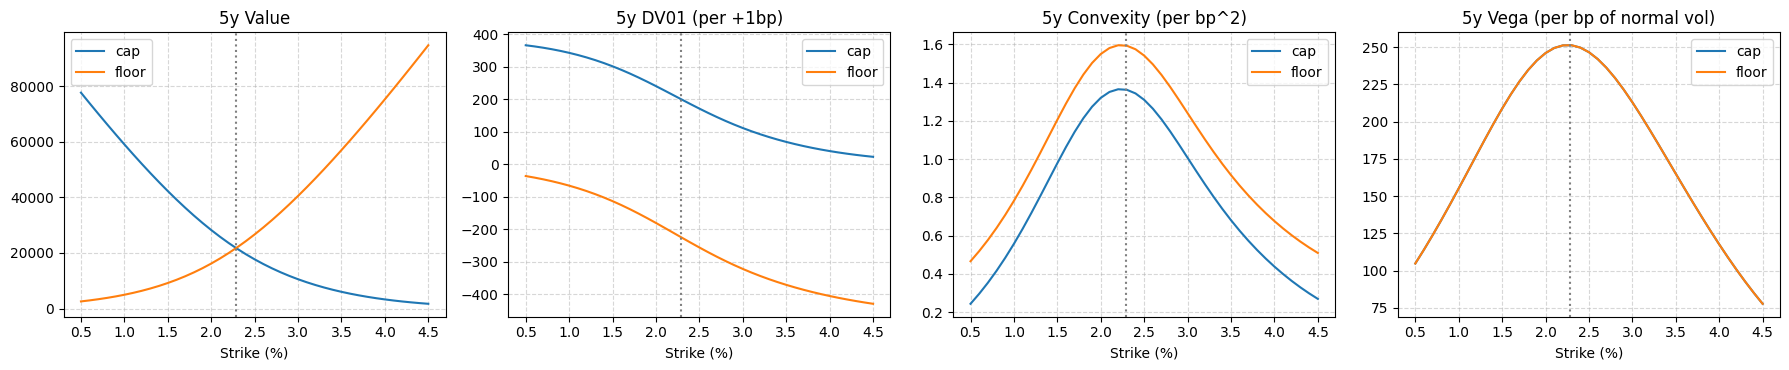

pillar (y),0.02,0.25,0.5,0.75,1,1.25,1.5,1.75,2,2.5,3,3.5,4,4.5,5
Cap 5y K=2.5%,0,0,-14.2673,0,-4.1539,0,-6.99992,0,-9.16889,-2.25922,-1.94754,-1.7176,-1.5419,-1.40535,214.577
Floor 5y K=2.5%,0,0,35.1091,0,-5.37512,0,-8.81242,0,-11.5594,-5.21329,-5.45172,-5.75845,-6.10607,-6.47956,-236.677


In [8]:
strikes = np.linspace(0.005, 0.045, 41)
measures = {"value": [], "DV01": [], "convexity": [], "vega": []}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for is_cap in [True, False]:
    values, dv01, conv, veg = [], [], [], []
    for k in strikes:
        c = CapFloor(5, k, is_cap=is_cap)
        r = curve_risk(pricer, c)
        values.append(r["value"]); dv01.append(r["DV01 (per +1bp)"]); conv.append(r["convexity (per bp^2)"]); veg.append(vega(pricer, c))
    for ax, y in zip(axes, [values, dv01, conv, veg]):
        ax.plot(100 * strikes, y, label="cap" if is_cap else "floor")
for ax, title in zip(axes, ["Value", "DV01 (per +1bp)", "Convexity (per bp^2)", "Vega (per bp of normal vol)"]):
    ax.axvline(100 * atm5, color="grey", linestyle=":"); ax.set_title(f"5y {title}"); ax.set_xlabel("Strike (%)")
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.tight_layout(); plt.show()
pd.concat({"Cap 5y K=2.5%": key_rate_risk(pricer, cap)["sensitivity (per +1bp)"],
           "Floor 5y K=2.5%": key_rate_risk(pricer, floor)["sensitivity (per +1bp)"]}, axis=1).T

## 6. Hull-White

**Calibration to the at-the-money caps** (1 to 5 years). The residuals are price errors divided by the market
vega, i.e. errors in bp of normal volatility. With constant $(a, \sigma)$, the caplet normal volatilities of
Hull-White decrease with the fixing date when $a > 0$: the model cannot produce the hump of the cap vol curve,
so the fit is imperfect and $a$ goes to its lower bound. A time-dependent $\sigma(t)$ would fix it.

In [9]:
atm_caps = []
for T in [1, 2, 3, 4, 5]:
    c = CapFloor(T, 0.0); atm_caps.append(c.with_strike(pricer.par_rate(c.swap())))
hw_cal = HullWhite(curve, a=0.03, sigma=0.008)
fit = hw_cal.calibrate(pricer, atm_caps)
print(hw_cal, fit)
pd.DataFrame({"market flat vol (bp)": [1e4 * cap_vols.flat_vol(c.maturity) for c in atm_caps],
              "Hull-White implied flat vol (bp)": [1e4 * pricer.implied_cap_vol(c, hw_cal.price(c)) for c in atm_caps]},
             index=[c.code for c in atm_caps])

HullWhite(a=0.0010, sigma=81.8bp) {'a': 0.0010000000000000076, 'sigma': 0.008177829891877509, 'RMSE (bp of normal vol)': 5.582542248018205, 'max error (bp)': 10.620810946763656}


,market flat vol (bp),Hull-White implied flat vol (bp)
Cap 1y,72,82.6208
Cap 2y,82,82.5971
Cap 3y,86,82.6002
Cap 4y,87,82.5922
Cap 5y,86,82.5807


**Smile.** Market caps here have a flat normal smile (an assumption); Hull-White is a Gaussian model, so its
implied normal volatility is almost flat in strike as well, with a slight skew.

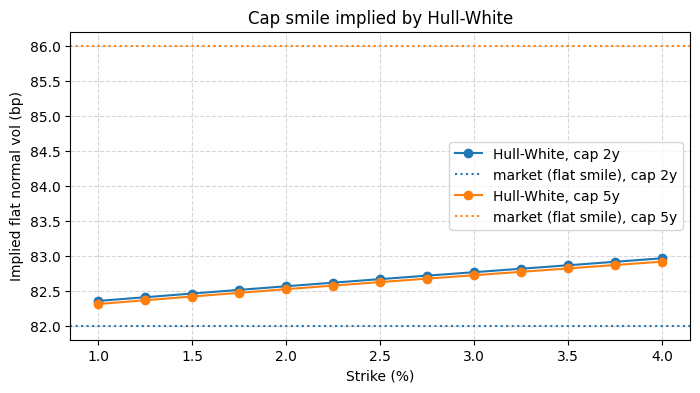

In [10]:
strikes = np.linspace(0.01, 0.04, 13)
fig, ax = plt.subplots(figsize=(8, 4))
for T in [2, 5]:
    ax.plot(100 * strikes, [1e4 * pricer.implied_cap_vol(CapFloor(T, k), hw_cal.price(CapFloor(T, k))) for k in strikes], "o-", label=f"Hull-White, cap {T}y")
    ax.axhline(1e4 * cap_vols.flat_vol(T), linestyle=":", color=ax.lines[-1].get_color(), label=f"market (flat smile), cap {T}y")
ax.set_xlabel("Strike (%)"); ax.set_ylabel("Implied flat normal vol (bp)"); ax.set_title("Cap smile implied by Hull-White")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.show()